## 0. 환경 검증

In [31]:
import shutil
import sys
import subprocess

print("Python:", sys.version.split()[0])
print("가상환경 경로:", sys.prefix)
print("가상환경 안에서 실행 중?", "venv" in sys.prefix)
print()

# OS 패키지 확인
print("Poppler  :", "OK" if shutil.which("pdftoppm") else "X 미설치 — Path 확인 후 재시작")
print("Tesseract:", "OK" if shutil.which("tesseract") else "X 미설치 — Path 확인 후 재시작")

# 파이썬 패키지 확인
print()
for mod in ["langchain", "unstructured", "chromadb", "tiktoken", "PIL"]:
    try:
        __import__(mod)
        print(f"{mod:14s}: OK")
    except ImportError:
        print(f"{mod:14s}: X 미설치")

Python: 3.11.9
가상환경 경로: c:\workspaces\multimodal-rag\venv
가상환경 안에서 실행 중? True

Poppler  : OK
Tesseract: OK

langchain     : OK
unstructured  : OK
chromadb      : OK
tiktoken      : OK
PIL           : OK


## 1. 라이브러리 임포트

In [3]:
import os
import re
import time
import uuid
import pickle
import base64
from pathlib import Path
from collections import Counter

from dotenv import load_dotenv
from unstructured.partition.pdf import partition_pdf
from langchain_text_splitters import CharacterTextSplitter

from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

try:
    from langchain_classic.retrievers.multi_vector import MultiVectorRetriever   # langchain 1.x
except ImportError:
    from langchain.retrievers.multi_vector import MultiVectorRetriever            # langchain 0.3

try:
    from langchain_core.stores import InMemoryStore                               # langchain 1.x
except ImportError:
    from langchain.storage import InMemoryStore                                   # langchain 0.3

from langchain_chroma import Chroma
from langchain_core.documents import Document
from langchain_openai import OpenAIEmbeddings

from langchain_core.runnables import RunnableLambda, RunnablePassthrough

print("임포트 완료")

임포트 완료


## 2. API 키 불러오기

In [4]:
# 프로젝트 루트: notebooks/ 안에서 열면 상위 폴더, 프로젝트 폴더에서 열면 현재 폴더
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

load_dotenv(PROJECT_ROOT / ".env")
openai_api_key = os.getenv("OPENAI_API_KEY")

if not openai_api_key:
    raise ValueError("환경변수 OPENAI_API_KEY 가 없습니다. .env 파일을 확인하세요.")
print(f"API KEY: {openai_api_key[:7]}...{openai_api_key[-4:]}")

# 키 유효청 체크
from openai import OpenAI, AuthenticationError
try:
    OpenAI(api_key=openai_api_key).models.list()
    print("API 키 유효성 확인 완료")
except AuthenticationError:
    raise ValueError("환경변수 OPENAI_API_KEY 가 유효하지 않습니다. .env 파일을 확인하세요.")

API KEY: sk-proj...Vq0A
API 키 유효성 확인 완료


## 3. 경로 설정

In [5]:
fname = "B_부동산시장_01_20p_텍스트+표+차트+차트(스캔)+이미지.pdf"
pdf_dir = PROJECT_ROOT / "data"
pdf_path = pdf_dir / fname

fpath = str(pdf_dir) + os.sep
# 원래 노트북 7번에서 했던것 위에 올리기
figures_dir = Path(fpath) / "figures"   # 추출 이미지 저장 폴더
# 원래 노트북 10번에서 했던것도 위에 올리기
output_dir = PROJECT_ROOT / "data" / "processed"    # 중간 결과(pkl) 저장
output_dir.mkdir(parents=True, exist_ok=True)   # data/processed/ 폴더 만듦

print("현재 위치     :", Path.cwd())
print("프로젝트 루트 :", PROJECT_ROOT)
print("PDF 절대 경로 :", pdf_path.resolve())
print("PDF 존재 여부 :", pdf_path.exists())
print("figures 폴더  :", figures_dir)

현재 위치     : c:\workspaces\multimodal-rag-assignment
프로젝트 루트 : c:\workspaces\multimodal-rag-assignment
PDF 절대 경로 : C:\workspaces\multimodal-rag-assignment\data\B_부동산시장_01_20p_텍스트+표+차트+차트(스캔)+이미지.pdf
PDF 존재 여부 : True
figures 폴더  : c:\workspaces\multimodal-rag-assignment\data\figures


## 4. 추출 함수 만들기

In [6]:
def extract_pdf_elements(path, fname):
    figures_dir = Path(path) / "figures"
    figures_dir.mkdir(parents=True, exist_ok=True)  # 폴더가 없으면 생성

    """PDF 파일에서 이미지, 테이블, 텍스트 블록을 추출합니다.
    
    path : 파일 경로 (추출된 이미지 파일이 저장될 위치)
    fname: 파일 이름
    """

    return partition_pdf(
        filename=path + fname,
        strategy="hi_res",                  # 정밀 추출 전략
        extract_images_in_pdf=True,         # 그림을 별도 파일로 저장
        extract_image_block_types=["Image", "Table"],      ## 저장할 요소 타입 (왠지 모르겠지만 이 줄을 뺴니 표 타입 저장이 안 됨)
        extract_image_block_output_dir=path + "figures",   ## 이미지 저장 폴더 (구 image_output_dir_path)
        infer_table_structure=True,         # 표 구조(행,열)를 추론
        chunking_strategy="by_title",       # '타이틀' 기준으로 분할
        max_characters=4000,                # 블록 최대 글자 수
        new_after_n_chars=3800,             # 이 글자 수 이후 새 블록 생성
        combine_text_under_n_chars=2000,    # 이 글자 수 이하 블록은 결합
        languages=["kor", "eng"],           # 깨진 표 읽기
    )

print("extract_pdf_elements 정의 완료")

extract_pdf_elements 정의 완료


## 5. 요소 분류 함수 만들기

In [7]:
def categorize_elements(raw_pdf_elements):
    """
    PDF에서 추출한 요소들을 테이블과 텍스트로 분류합니다.

    raw_pdf_elements: unstructured.documents.elements 리스트
    """
    tables = []
    texts = []

    for element in raw_pdf_elements:
        if "unstructured.documents.elements.Table" in str(type(element)):
            tables.append(str(element))
        elif "unstructured.documents.elements.CompositeElement" in str(type(element)):
            texts.append(str(element))

    return texts, tables


print("categorize_elements 정의 완료")

categorize_elements 정의 완료


## 6. 추출 & 실행

In [8]:
if figures_dir.exists():
    existing = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
else:
    existing = []
print("실행 전 figures/ 에 있는 이미지:", len(existing), "개  (0 이어야 정상)")

start = time.time()

raw_pdf_elements = extract_pdf_elements(fpath, fname)
print("PDF 폴더:", Path(fpath).resolve())
print("PDF 파일:", (Path(fpath) / fname).resolve())
print("이미지 저장 위치:", (Path(fpath) / "figures").resolve())

print(f"추출 완료 — {time.time() - start:.1f}초 소요")
print("추출된 전체 요소 수:", len(raw_pdf_elements))

texts, tables = categorize_elements(raw_pdf_elements)

print("텍스트 블록 수:", len(texts))
print("표 블록 수    :", len(tables))
print()

Thank you for using Unstructured Open Source! Try Unstructured's commercial offering for improved output quality. 10,000 free pages to start. Learn more: https://transform.unstructured.io/?utm_source=unstructured_oss Hide this notice: UNSTRUCTURED_DISABLE_NOTICE=1


실행 전 figures/ 에 있는 이미지: 0 개  (0 이어야 정상)


Loading weights: 100%|██████████| 367/367 [00:00<00:00, 2228.18it/s]


PDF 폴더: C:\workspaces\multimodal-rag-assignment\data
PDF 파일: C:\workspaces\multimodal-rag-assignment\data\B_부동산시장_01_20p_텍스트+표+차트+차트(스캔)+이미지.pdf
이미지 저장 위치: C:\workspaces\multimodal-rag-assignment\data\figures
추출 완료 — 109.6초 소요
추출된 전체 요소 수: 9
텍스트 블록 수: 7
표 블록 수    : 2



## 7. 어떤 요소가 나왔는지 집계

In [9]:
type_counts = Counter(str(type(el)).split(".")[-1].strip("'>") for el in raw_pdf_elements)

for element_type, count in type_counts.most_common():
    print(f"{element_type:22s}: {count}개")

CompositeElement      : 7개
Table                 : 2개


## 8. 추출된 이미지 확인

In [10]:
if figures_dir.exists():
    image_files = sorted(
        f for f in figures_dir.iterdir()
        if f.suffix.lower() in (".jpg", ".jpeg", ".png")
    )
    print(f"추출된 이미지 전체: {len(image_files)}개\n")
    for f in image_files[:10]:
        print(f"  {f.name}  ({f.stat().st_size // 1024} KB)")
else:
    print("X figures 폴더가 없습니다.")
    print("  → TODO 2, TODO 3 을 다시 확인하세요.")

추출된 이미지 전체: 26개

  figure-1-1.jpg  (203 KB)
  figure-11-14.jpg  (115 KB)
  figure-12-15.jpg  (72 KB)
  figure-13-16.jpg  (109 KB)
  figure-14-17.jpg  (127 KB)
  figure-15-18.jpg  (68 KB)
  figure-15-19.jpg  (58 KB)
  figure-16-20.jpg  (59 KB)
  figure-16-21.jpg  (69 KB)
  figure-17-22.jpg  (103 KB)


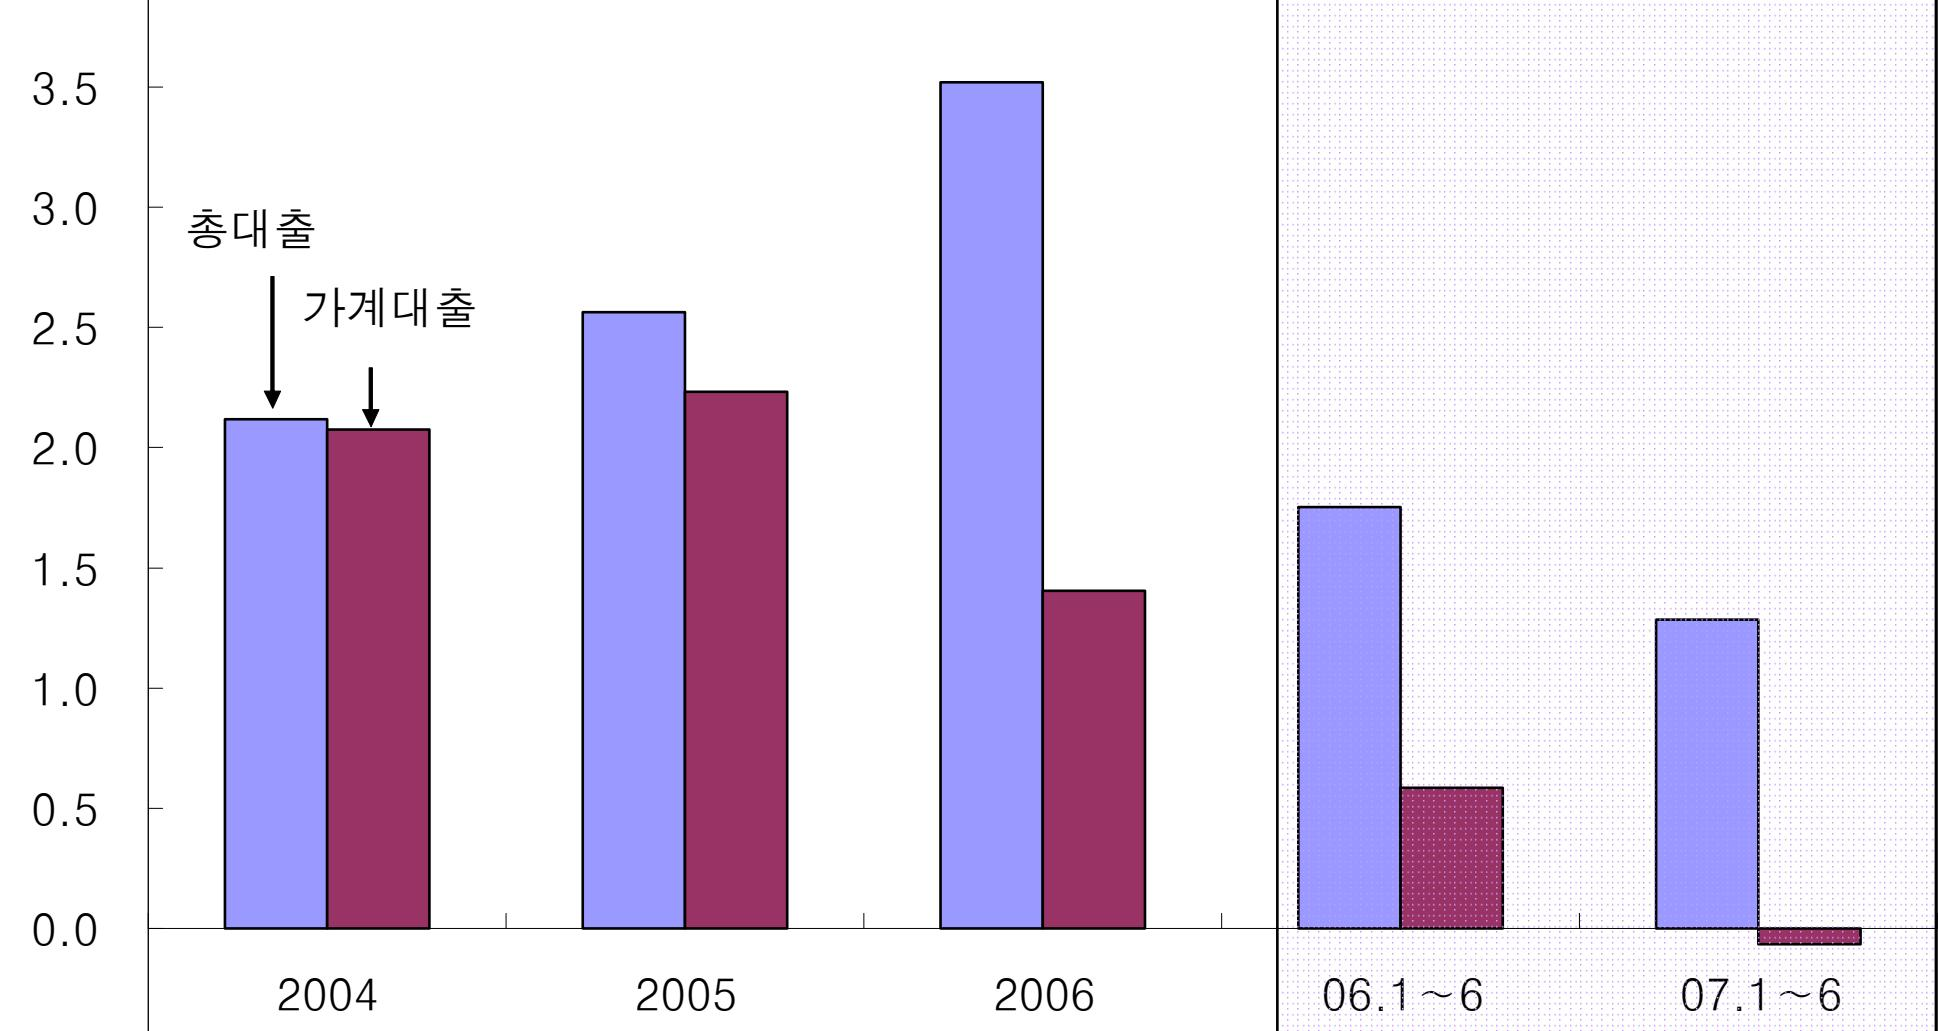

In [11]:
# 첫 번째 이미지를 노트북에서 직접 확인
from IPython.display import Image, display

if figures_dir.exists() and image_files:
    display(Image(filename=str(image_files[0]), width=500))
else:
    print("표시할 이미지가 없습니다.")

## 9. 텍스트 분할과 비교

In [12]:
text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=2000,       # 각 텍스트 블록의 최대 크기
    chunk_overlap=200,     # 청크 간 겹칠 글자수
)

joined_texts = " ".join(texts)
texts_2k_token = text_splitter.split_text(joined_texts)

print("원본 블록 수  :", len(texts))
print("분할 후 블록 수:", len(texts_2k_token))
print("전체 글자 수  :", len(joined_texts))
print()
print("=" * 60)
print("[분할 texts_2k_token[0]] 앞 300자")
print("=" * 60)
print(texts_2k_token[0][:300])

원본 블록 수  : 7
분할 후 블록 수: 14
전체 글자 수  : 17974

[분할 texts_2k_token[0]] 앞 300자
( 가 계 대출 위축 및 이에 따른 은 행 대 출 전 략 변화)

[| 주 택 담 보 대 출 규제 및 부 동 산 시장 위 축 으 로 2006 년 이후 가 계 대 출 이 크게 둔화

ㅇ 가 계 대 출 은 총 원 화 대출 SAW 차지하는 비 중 이 2005 년 87% 에 서 2006 년 40% 로 급 감 한 후 금년 상 반 기 에 는 소 폭 의 순 상 환 으 로 전환

예 금 은행 가 겨 추이

( 기

간 중

증 감 액 , 억원)

2005

여간

2006

상반

007 상반

가 Al 대 출 22.326(87.1) 14,043


In [13]:
# 추출 결과 저장 (다음에 다시 쓸 수 있도록)
with open(output_dir / "extracted.pkl", "wb") as f:
    pickle.dump(
        {"texts": texts, "tables": tables, "texts_2k_token": texts_2k_token},
        f,
    )

print("저장 완료:", output_dir / "extracted.pkl")

저장 완료: c:\workspaces\multimodal-rag-assignment\data\processed\extracted.pkl


# [Part.2] 텍스트, 표 요약

## 10. 요약 체인 만들기 (LLM)

In [14]:
def generate_text_summaries(texts, tables, summarize_texts=False):
    """
    텍스트 및 표 데이터를 요약하여 검색에 활용할 요약본을 생성합니다.

    texts          : 텍스트 리스트
    tables         : 표 리스트
    summarize_texts: 텍스트 요약을 활성화할지 여부
    """

    # 한국어 요약 프롬프트
    prompt_text_kor = """당신은 표와 텍스트를 요약하여 검색에 활용할 수 있도록 돕는 도우미입니다.
        이 요약본들은 임베딩되어 원본 텍스트나 표 요소를 검색하는 데 사용될 것입니다.
        주어진 표나 텍스트의 내용을 검색에 최적화된 간결한 요약으로 작성해주세요.
        요약할 표 또는 텍스트: {element}"""

    # 영어 버전 (한국어 결과가 부정확할 때 교체)
    # prompt_text_eng = """You are an assistant tasked with summarizing tables and text for retrieval.
    # These summaries will be embedded and used to retrieve the raw text or table elements.
    # Give a concise summary of the table or text that is well optimized for retrieval.
    # Table or text: {element}"""

    # 프롬프트 템플릿
    prompt = ChatPromptTemplate.from_template(prompt_text_kor)
     # 모델
    model = ChatOpenAI(temperature=0, model="gpt-4o-mini")

    # 요약 체인 = 입력 포장 | 프롬프트 | LLM | 출력 파서
    summarize_chain = {"element": lambda x: x} | prompt | model | StrOutputParser()

    # 빈 리스트
    text_summaries = []
    table_summaries = []

    # 텍스트 요약을 켠 경우 batch로, 아니면 원문 그대로 사용
    if texts and summarize_texts:
        text_summaries = summarize_chain.batch(texts, {"max_concurrency": 5})
    elif texts:
        text_summaries = texts

    # 표는 항상 batch로
    if tables:
        table_summaries = summarize_chain.batch(tables, {"max_concurrency": 5})

    # 반환
    return text_summaries, table_summaries


print("generate_text_summaries 정의 완료")

generate_text_summaries 정의 완료


## 11. 텍스트, 표 요약 실행 및 결과 확인

In [15]:
start = time.time()

text_summaries, table_summaries = generate_text_summaries(texts_2k_token, tables, summarize_texts=True)

print(f"요약 완료 => {time.time() - start:.1f}초 걸림")
print("텍스트 요약 수:", len(text_summaries))
print("표 요약 수:", len(table_summaries))

요약 완료 => 31.2초 걸림
텍스트 요약 수: 14
표 요약 수: 2


In [16]:
# 요약 품질 확인
print("-" * 60)
print("[원본 texts_2k_token[0] 앞 300자]")
print(texts_2k_token[0][:300])
print("-" * 60)
print("[요약 text_summaries[0]]")
print(text_summaries[0])
origin = len(texts_2k_token[0])
summ = len(text_summaries[0])
print(f"압축률: {origin}자 -> {summ}자 ({summ / origin * 100:.1f}%)")


------------------------------------------------------------
[원본 texts_2k_token[0] 앞 300자]
( 가 계 대출 위축 및 이에 따른 은 행 대 출 전 략 변화)

[| 주 택 담 보 대 출 규제 및 부 동 산 시장 위 축 으 로 2006 년 이후 가 계 대 출 이 크게 둔화

ㅇ 가 계 대 출 은 총 원 화 대출 SAW 차지하는 비 중 이 2005 년 87% 에 서 2006 년 40% 로 급 감 한 후 금년 상 반 기 에 는 소 폭 의 순 상 환 으 로 전환

예 금 은행 가 겨 추이

( 기

간 중

증 감 액 , 억원)

2005

여간

2006

상반

007 상반

가 Al 대 출 22.326(87.1) 14,043
------------------------------------------------------------
[요약 text_summaries[0]]
### 요약: 가계 대출 위축 및 은행 대출 전략 변화

- **가계 대출 현황**: 2006년 이후 가계 대출이 크게 둔화, 2005년 87%에서 2006년 40%로 감소. 2023년 상반기에는 소폭 증가.
- **주택 시장 동향**: 주택 매매가격 상승, 허가 및 착공 감소. 향후 가격 하락세 예상, 주택 공급 약화 우려.
- **매매 및 거래량**: 7월 주택 매매가격 상승 전환, 수도권 거래량 증가. 비수도권도 일부 증가.
- **임대 시장**: 전세 및 월세 가격 하락폭 축소, 부진 완화.
- **주택 공급 지표**: 주택 인허가 1.8만 호로 전년 대비 50% 감소, 착공도 71.7% 감소하여 공급 위축 심화. 

이 요약은 가계 대출과 주택 시장의 변화 및 관련 통계를 간결하게 정리하여 검색에 최적화된 형태로 제공합니다.
압축률: 1493자 -> 415자 (27.8%)


In [17]:
if table_summaries:
    print(f"표 요약 => {len(table_summaries)} 건 생성됨 \n")
    print(f"[표 요약 예시]")
    print(table_summaries[0])
    
    for i, (table, summary) in enumerate(zip(tables[:2], table_summaries[:2])):
        print("=" * 60)
        print(f"[표 {i + 1} 원본 (앞 300자)]")
        print(table[:300])
        print(f"[표 {i + 1} 요약]")
        print(summary)
else:
    print("표 요약이 비어 있습니다. 원인: 1) strategy='hi_res' 확인 2) 진짜 표인지, 그림으로 그린 표인지 확인")

표 요약 => 2 건 생성됨 

[표 요약 예시]
**요약:**  
- **주관 부서:** 국토교통부  
- **계획:**  
  - 제2차 장기 주거 종합 계획 (2013~2022)  
  - 제2차 장기 주거 종합 계획 (2018~2022)  
  - 매년 주거 종합 계획 수립 (2018~2023)  
- **연도별 계획:**  
  - 2018년: 주거 종합 계획  
  - 2019년: 주거 종합 계획  
  - 2020년: 주거 종합 계획  
  - 2021년: 주거 종합 계획  
  - 2022년: 주거 종합 계획  
  - 2023년: 주거 종합 계획  
[표 1 원본 (앞 300자)]
요 법 정 계획 차기 계획 수 립 년 도 주 관 부서 제 2 차 장 기 주 거 종 합 계 획 (2013~2022) 기 본 계획 제 2 차 장 기 주 거 종 합 계 획 (2018~2022) 수 정 계획 - 국 토 교통부 2018 년 주 거 종 합 계 획 매년 국 토 교통부 2019 년 주 거 종 합 계획 매년 국 토 교통부 2020 년 주 거 종 합 계획 매년 국 토 교통부 이 행 계획 20214 주 거 종 합 계획 매년 국 토 교통부 2022 년 주 거 종 합 계 획 매년 국 토 교통부 2023 년 주 거 종 합 계획 매년 국 토 
[표 1 요약]
**요약:**  
- **주관 부서:** 국토교통부  
- **계획:**  
  - 제2차 장기 주거 종합 계획 (2013~2022)  
  - 제2차 장기 주거 종합 계획 (2018~2022)  
  - 매년 주거 종합 계획 수립 (2018~2023)  
- **연도별 계획:**  
  - 2018년: 주거 종합 계획  
  - 2019년: 주거 종합 계획  
  - 2020년: 주거 종합 계획  
  - 2021년: 주거 종합 계획  
  - 2022년: 주거 종합 계획  
  - 2023년: 주거 종합 계획  
[표 2 원본 (앞 300자)]
일 반 회 계 ( 주 택 부문) 합계 29,397 32,324 2,927 1

# [Part.3] 이미지 요약

## 12. 이미지를 base64로 포장

In [18]:
# 함수정의
def encode_image(image_path):
    with open(image_path, "rb") as image_file:
        return base64.b64encode(image_file.read()).decode("utf-8")


def image_summarize(img_base64, prompt):
    """이미지 요약 생성 (gpt-4o-mini 는 비전 기능을 포함합니다)"""
    chat = ChatOpenAI(model="gpt-4o-mini", max_tokens=1024)
    msg = chat.invoke([
        HumanMessage(content=[
            {"type": "text", "text": prompt},
            {"type": "image_url",
             "image_url": {"url": f"data:image/jpeg;base64,{img_base64}"}},   # data:image/jpeg;base64, 접두사 필수
        ])
    ])
    return msg.content


# 프롬프트 (차트 요약 디벨롭 / 차트제목, 단위, 범례 등등 추가)
prompt_kor = """You are an assistant tasked with summarizing images for retrieval.
These summaries will be embedded and used to retrieve the raw image.
Provide a concise summary of the image that is well optimized for retrieval.
If the image is a chart or a table, you MUST include:
- the topic of the chart (its title; if no title is visible, infer the topic from the labels and the legend),
- the chart type, the axis names and the units (copy the units exactly as shown; never guess a unit),
- every series or category name and the years or periods shown,
- the key numbers, and state the highest and the lowest values together with their year or category,
- the main trend.
If the image is only a logo, icon, or decoration, say so in one short sentence.
The summary should be written in Korean (Hangul)."""

# 그림이 문자열이 되었다는 것을 눈으로 확인
sample_b64 = encode_image(image_files[0])
print("원본 파일:", image_files[0].name, "/ 문자열 길이:", len(sample_b64), "자")
print("앞 100자:", sample_b64[:100])
print()
print("[테스트 요약]")
print(image_summarize(sample_b64, prompt_kor))



원본 파일: figure-1-1.jpg / 문자열 길이: 278360 자
앞 100자: /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx

[테스트 요약]
주제: 총대출 및 가계대출 변화  
차트 유형: 세로 막대 그래프  
축 이름 및 단위: Y축 - 대출액(단위: 불명확), X축 - 연도  
범례: 총대출(파란색), 가계대출(보라색)  
연도: 2004, 2005, 2006, 06.1~6, 07.1~6  
주요 수치:  
- 2004년 총대출: 2.0, 가계대출: 2.0  
- 2005년 총대출: 2.5, 가계대출: 1.5  
- 2006년 총대출: 3.0, 가계대출: 1.0  
- 06.1~6 총대출: 2.5, 가계대출: 0.5  
- 07.1~6 총대출: 1.5, 가계대출: 0.3  
최고값: 2006년 총대출 3.0, 최저값: 07.1~6 가계대출 0.3  
주요 추세: 총대출은 2004년부터 2006년까지 증가한 후 감소하였고, 가계대출은 2005년에 감소세를 보임.


In [19]:
start = time.time()

img_base64_list = []   # Base64 원본 (답변 생성 시 VLM 에 다시 전달)
image_summaries = []   # 요약 (검색용)

for img_file in image_files:
    base64_image = encode_image(img_file)
    img_base64_list.append(base64_image)
    image_summaries.append(image_summarize(base64_image, prompt_kor))

print(f"이미지 요약 완료 => {time.time() - start:.1f}초, {len(image_summaries)}장")

이미지 요약 완료 => 120.7초, 26장


[0] figure-1-1.jpg


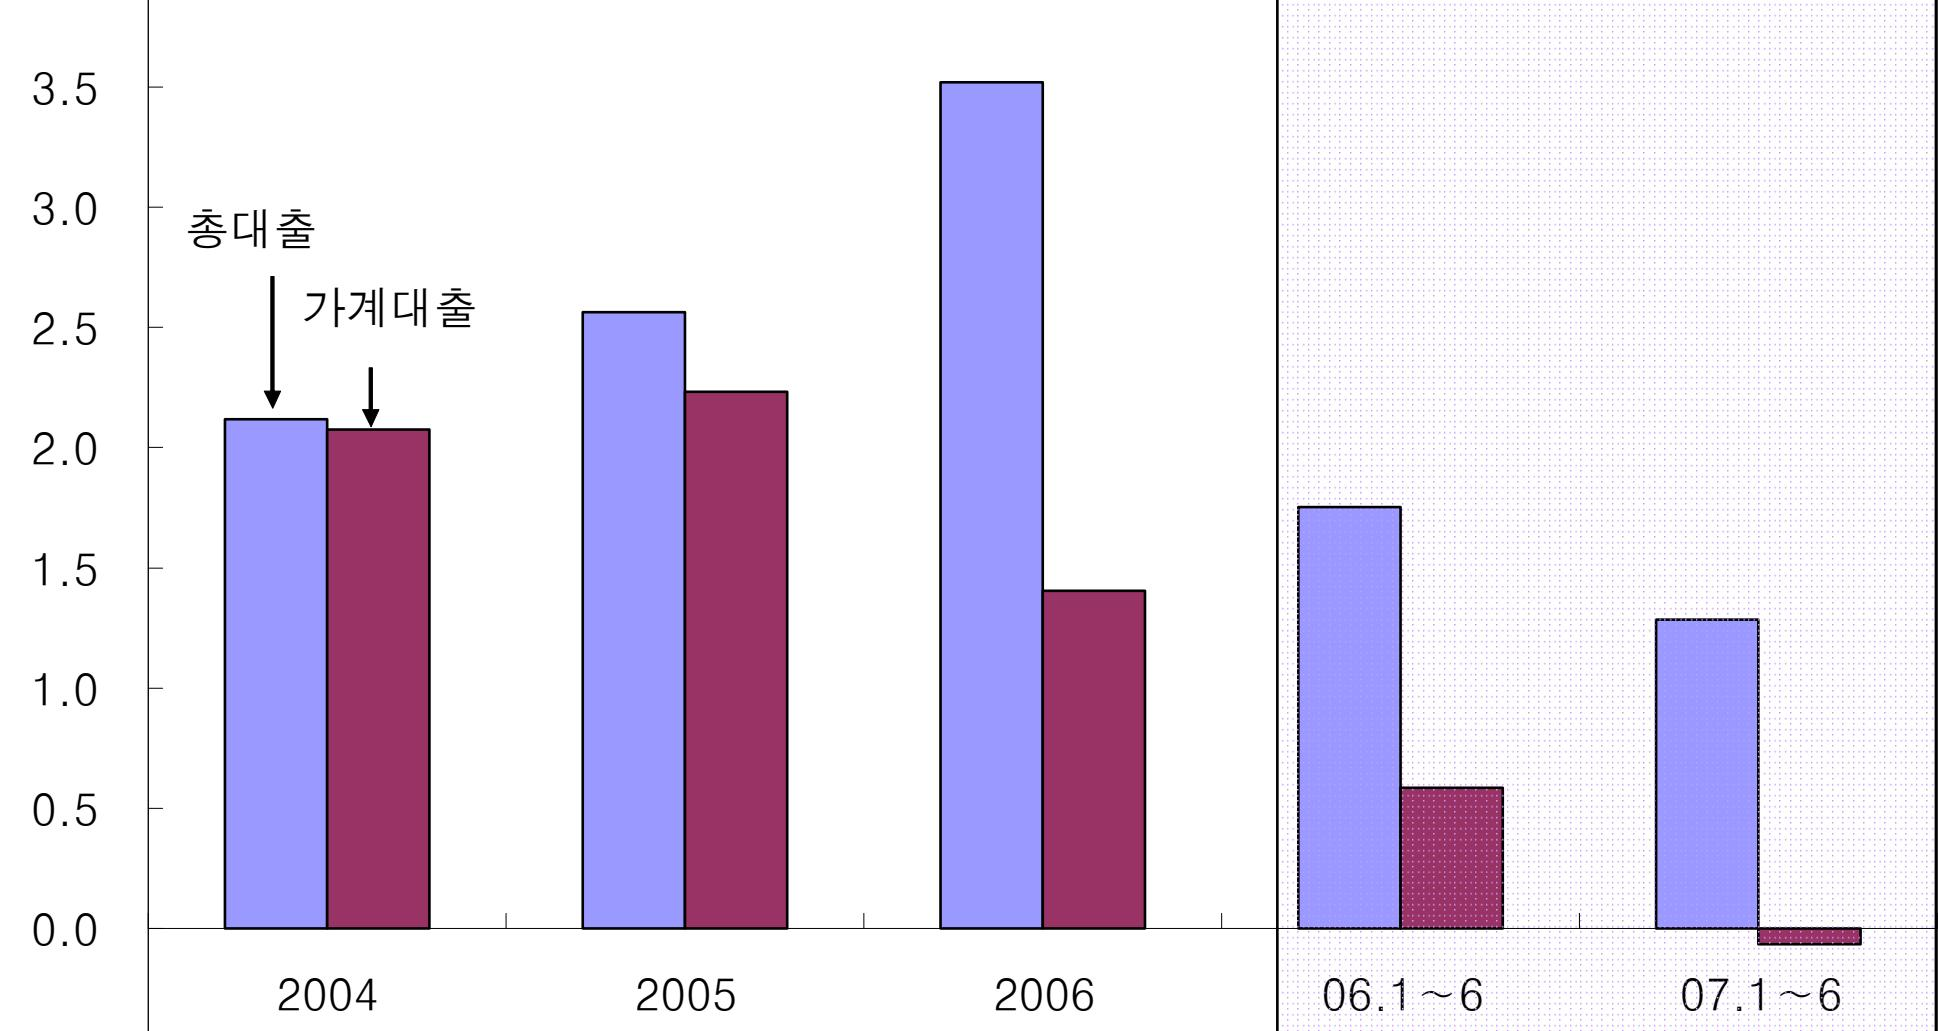

요약: 그래프 제목: 총대출 및 가계대출  
차트 유형: 세로 막대 그래프  
축 이름 및 단위:  
- y축: 대출 금액 (단위 없음)  
- x축: 연도 (2004, 2005, 2006) 및 기간 (06.1~6, 07.1~6)  

범례:  
- 총대출 (파란색)  
- 가계대출 (보라색)  

주요 수치:  
- 2004년 총대출: 2.0, 가계대출: 1.8  
- 2005년 총대출: 2.5, 가계대출: 2.0  
- 2006년 총대출: 3.2, 가계대출: 1.6  
- 06.1~6 총대출: 2.8, 가계대출: 0.5  
- 07.1~6 총대출: 0.9, 가계대출: 0.4  

가장 높은 수치: 2006년 총대출 3.2  
가장 낮은 수치: 07.1~6 가계대출 0.4  

주요 추세: 총대출은 2004년부터 2006년까지 증가하였으나, 이후 감소 추세로 전환됨. 가계대출은 전반적으로 감소세를 보임.

[1] figure-11-14.jpg


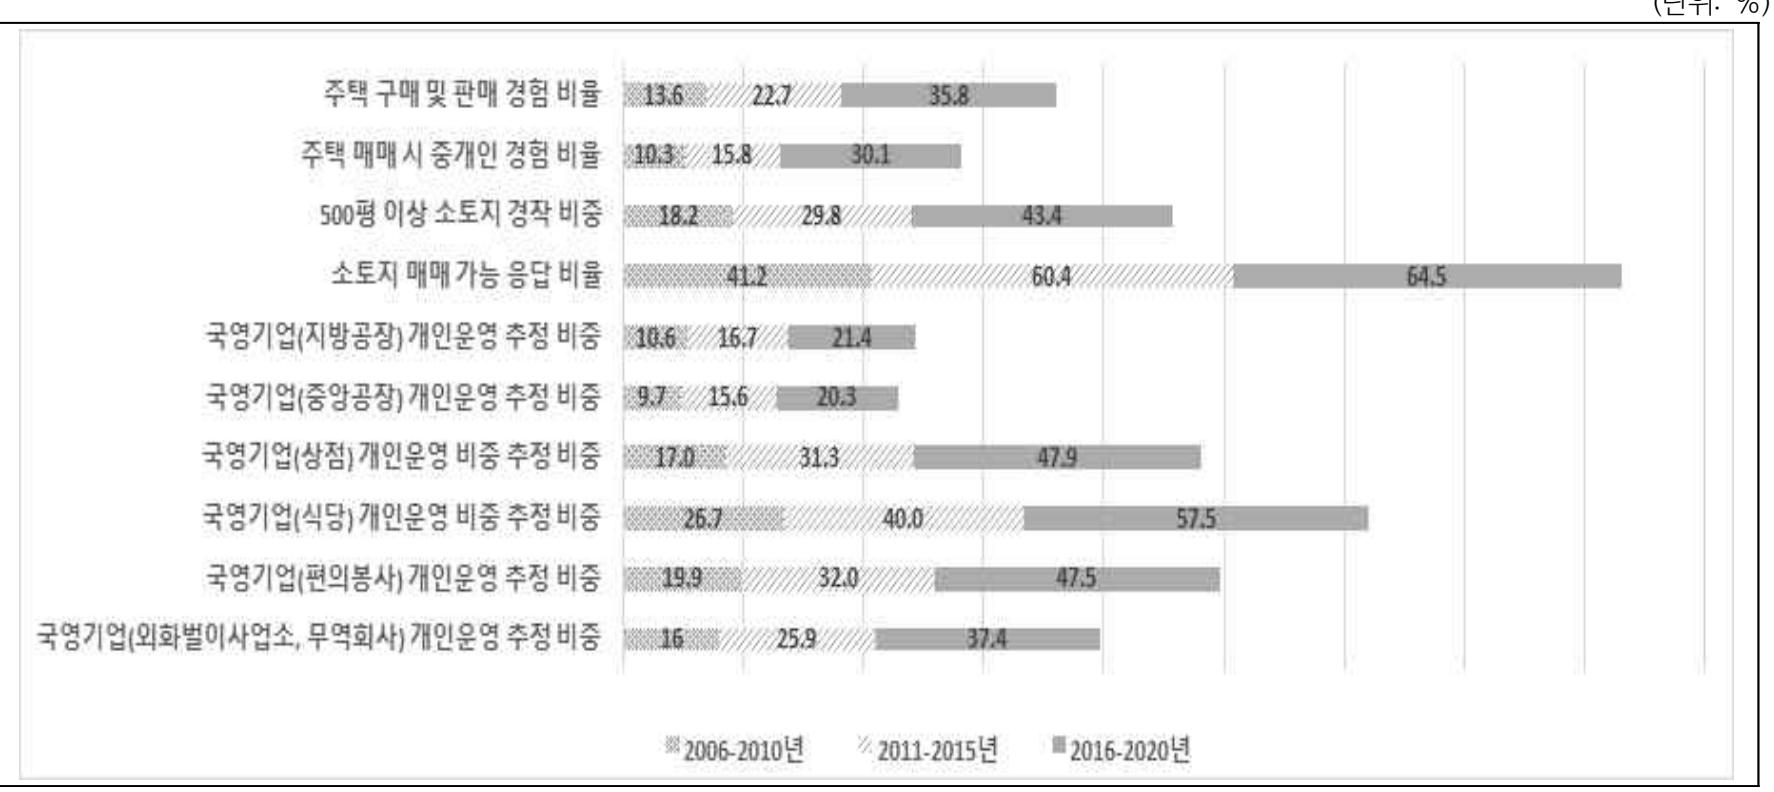

요약: 이 이미지는 "주택 구매 및 판매 경험 비율"에 대한 수평 막대 그래프입니다. 

- **축 이름**: 
  - X축: 비율 (%) 
  - Y축: 주택 구매 및 판매 경험 관련 카테고리
- **단위**: %
- **시리즈/카테고리**: 
  - 주택 구매 및 판매 경험 비율
  - 주택 매매 시 개인인 감 비율
  - 500평 이상 소토지 경작 비율
  - 소토지 매매 가능 응답 비율
  - 국영기업(지방공장) 개인운영 비율
  - 국영기업(중앙공장) 개인운영 비율
  - 국영기업(상점) 개인운영 비율
  - 국영기업(식당) 개인운영 비율
  - 국영기업(편의봉사) 개인운영 비율
  - 국영기업(외화벌이사업소, 무역회사) 개인운영 비율

- **주요 숫자**: 
  - 최고값: 64.5% (소토지 매매 가능 응답 비율, 2016-2020년)
  - 최저값: 10.3% (주택 매매 시 개인인 감 비율, 2006-2010년)

- **주요 경향**: 전반적으로 주택 구매 및 판매 경험과 관련된 비율이 증가하는 추세를 보임.

[2] figure-12-15.jpg


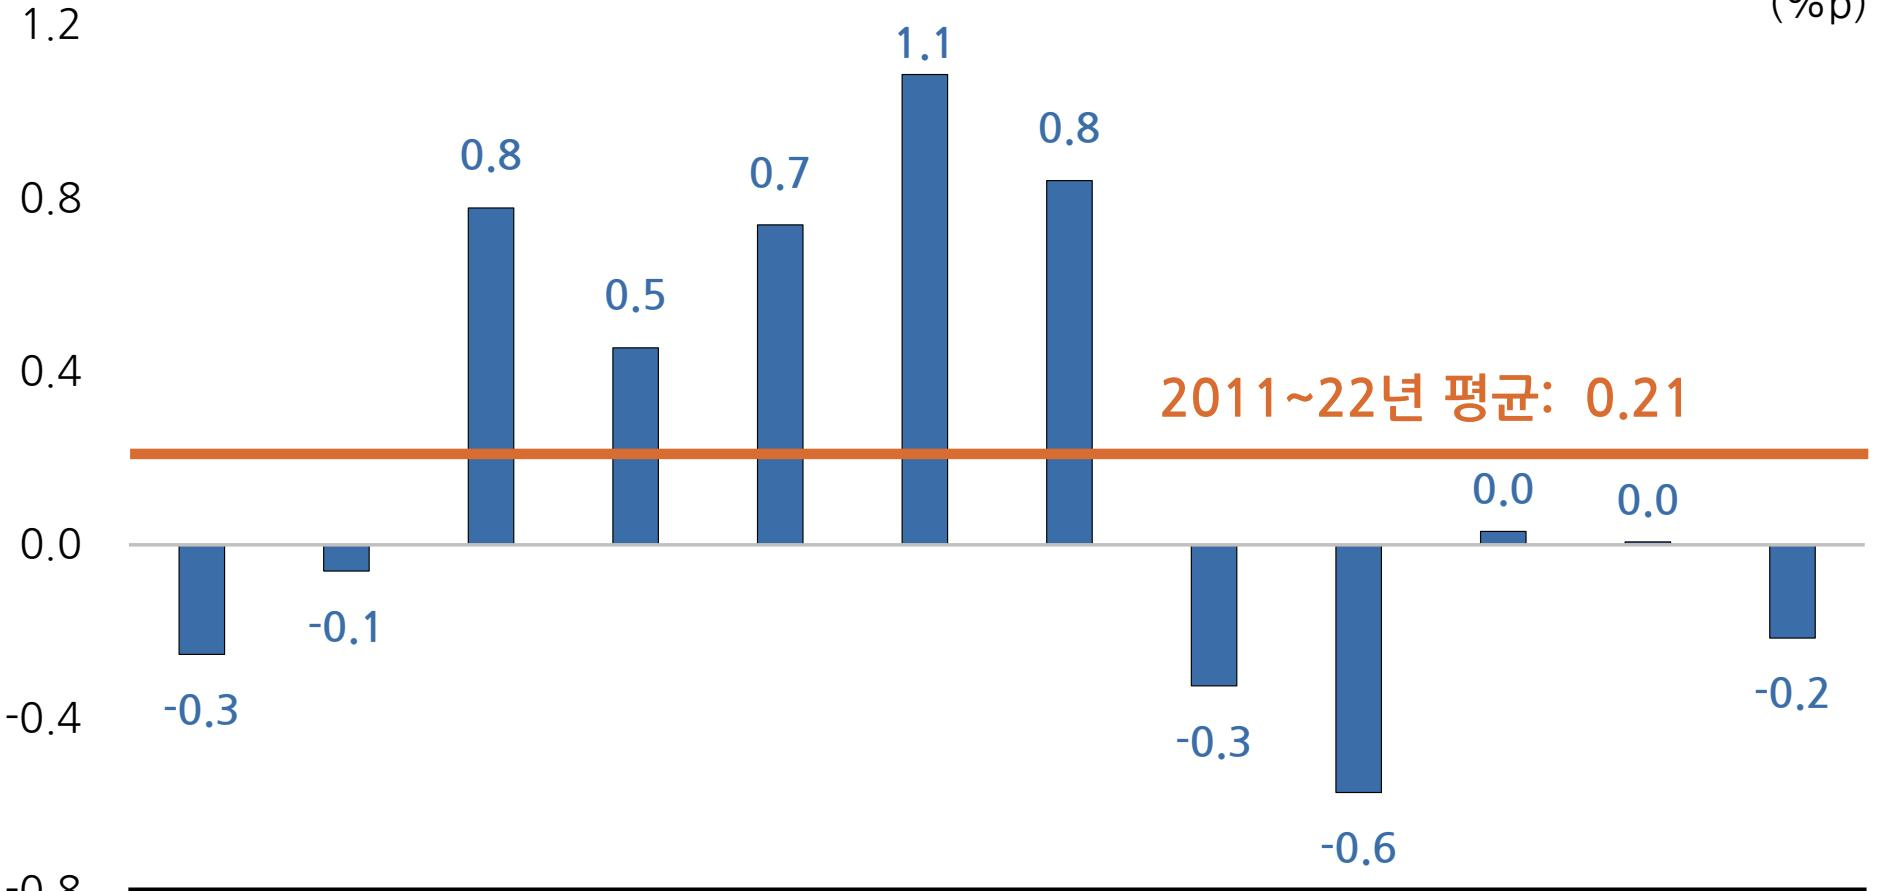

요약: 차트 제목: 미지정  
차트 유형: 세로 막대 그래프  
축 이름: Y축 (%p)  
연도/기간: 데이터 없음  
주요 수치: 최고 1.1 (%p) / 최저 -0.6 (%p)  
주요 트렌드: 2011~22년 평균 0.21로 전체적으로 변동성이 있음.

[3] figure-13-16.jpg


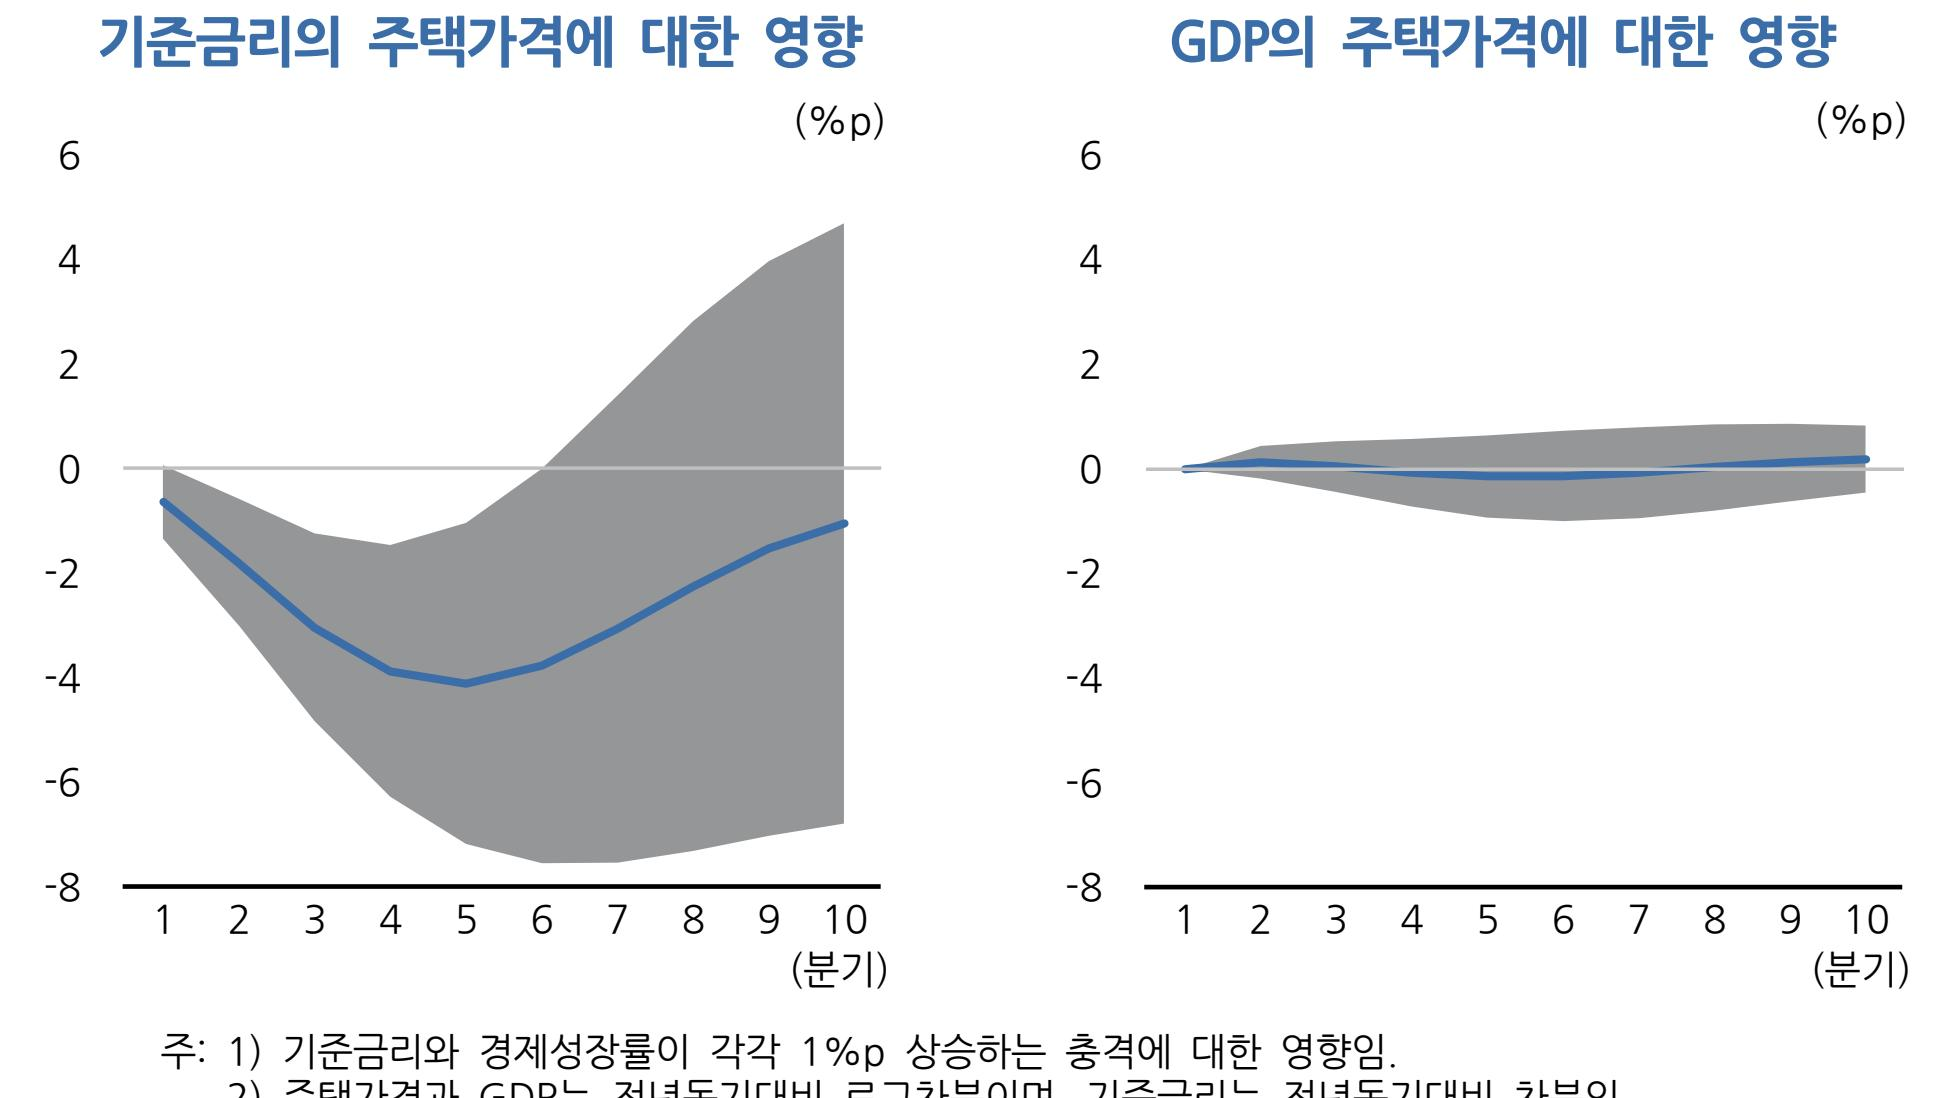

요약: 차트 제목: 기준금리의 주택가격에 대한 영향 및 GDP의 주택가격에 대한 영향  
차트 유형: 면적 차트  
축 이름: 왼쪽 - (%p), 오른쪽 - (%p)  
기간: 1분기 ~ 10분기  

주요 수치:  
- 기준금리 영향: 1분기 -6, 10분기 0, 최고치 -2 (8분기), 최저치 -8 (1분기)  
- GDP 영향: 1분기 -4, 10분기 0, 최고치 0 (10분기), 최저치 -6 (1분기)  

주요 경향: 기준금리의 영향은 시간이 지남에 따라 상승하는 경향을 보이며 GDP의 영향은 비교적 일정하다.

[4] figure-14-17.jpg


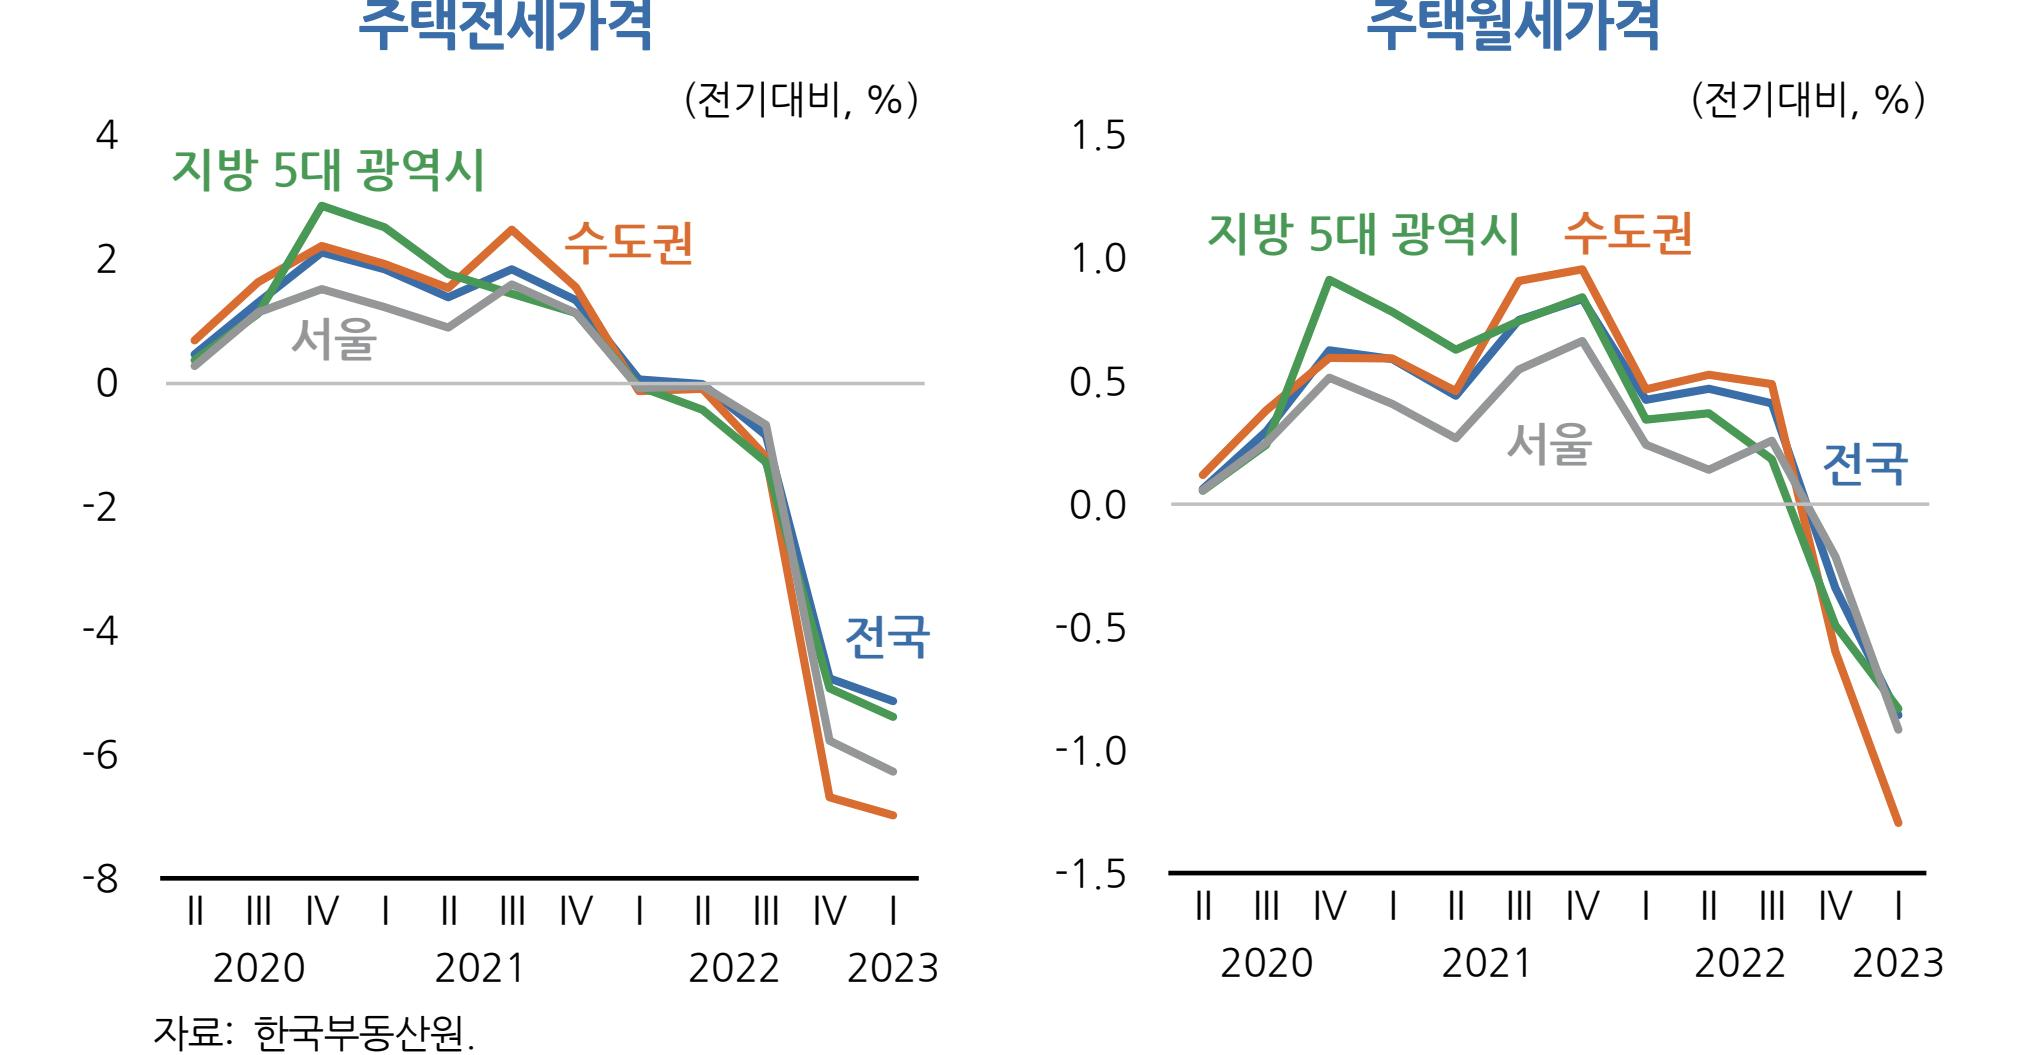

요약: 이 이미지는 "주택전세가격"과 "주택월세가격"에 대한 선 그래프입니다. 

- **주제**: 주택전세가격, 주택월세가격
- **차트 유형**: 선 그래프
- **축 이름 및 단위**: 전기대비, %
- **범례**: 서울, 수도권, 지방 5대 광역시, 전국
- **주요 수치**:
  - 주택전세가격:
    - 최고치: 4% (2021년 III분기, 지방 5대 광역시)
    - 최저치: -8% (2022년 I분기, 전국)
  - 주택월세가격:
    - 최고치: 1.5% (2022년 I분기, 수도권)
    - 최저치: -1.5% (2023년 I분기, 전국)
- **주요 경향**: 주택전세가격은 2022년부터 급격한 하락세를 보였고, 주택월세가격은 점진적인 하락과 상승을 반복함.

[5] figure-15-18.jpg


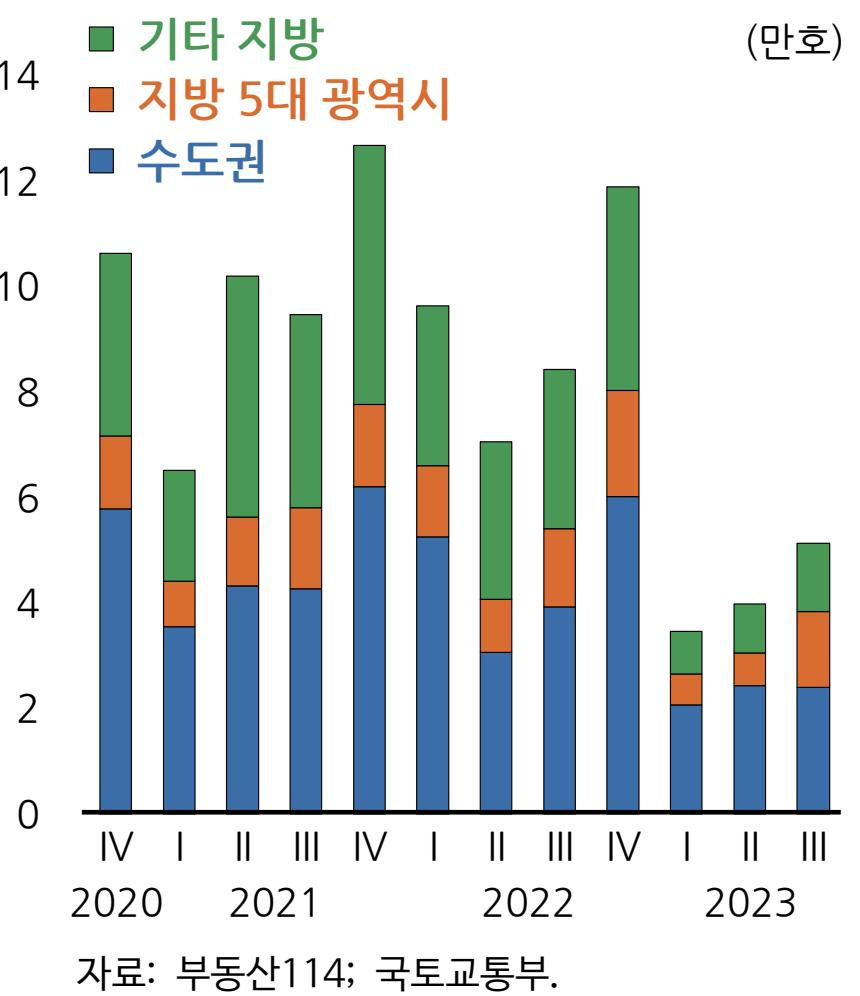

요약: 이 이미지는 "수도권 및 지방 주택 가격 변화"를 주제로 한 세로 막대 그래프입니다. X축은 연도(2020년 IV, 2021년 I, II, III, IV, 2022년 I, II, III, IV, 2023년 I, II, III)이고, Y축은 주택 가격(단위: 없음)을 나타냅니다. 세 가지 카테고리로는 "기타 지방" (초록색), "지방 5대 광역시" (주황색), "수도권" (파란색)이 있습니다. 

- 2022년 IV에서 '수도권'이 가장 높아 약 14에 이르렀고, 이는 그래프의 가장 높은 값입니다.
- 가장 낮은 값은 2023년 III에서 나타나는 '지방 5대 광역시'로, 값은 약 2입니다.

전반적으로 수도권의 주택 가격은 상승 추세를 보이며, 지방 5대 광역시는 상대적으로 낮은 가격을 유지하고 있습니다.



In [20]:
# 요약 품질 검증
for i, (img_file, summary) in enumerate(zip(image_files[:6], image_summaries[:6])):
    print("=" * 60)
    print(f"[{i}] {img_file.name}")
    print("=" * 60)
    display(Image(filename=str(img_file), width=450))
    print("요약:", summary)
    print()

In [21]:
# 토큰 사용량 추정 (텍스트 요약 기준. 이미지 토큰은 해상도에 따라 달라 포함되지 않음)
import tiktoken

enc = tiktoken.encoding_for_model("gpt-4o-mini")
input_tokens = sum(len(enc.encode(t)) for t in texts_2k_token)
output_tokens = sum(len(enc.encode(s)) for s in text_summaries)

print("텍스트 요약 토큰 사용량 (추정)")
print(f"  입력 : {input_tokens:,} 토큰")
print(f"  출력 : {output_tokens:,} 토큰")
print(f"  합계 : {input_tokens + output_tokens:,} 토큰")
print("요약한 이미지 수:", len(image_summaries), "장")

# 요약 결과 저장
with open(output_dir / "summaries.pkl", "wb") as f:
    pickle.dump(
        {
            "text_summaries": text_summaries,
            "table_summaries": table_summaries,
            "image_summaries": image_summaries,
            "img_base64_list": img_base64_list,
        },
        f,
    )
print("저장 완료:", output_dir / "summaries.pkl")

텍스트 요약 토큰 사용량 (추정)
  입력 : 11,414 토큰
  출력 : 3,514 토큰
  합계 : 14,928 토큰
요약한 이미지 수: 26 장
저장 완료: c:\workspaces\multimodal-rag-assignment\data\processed\summaries.pkl


# [Part.3] 저장.검색 / 다중 벡터 검색기

## 12. 검색기 만들기

In [22]:
# 요약문이 들어갈 벡터 DB
vectorstore = Chroma(
    collection_name="multimodal_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)

# 원본이 들어갈 저장소 (= 서가)
store = InMemoryStore()

# 연결 키 (= 청구기호)
id_key = "doc_id"

# 검색 개수 k=6 (텍스트전용 RAG랑 같은 값으로)
retriever = MultiVectorRetriever(
    vectorstore=vectorstore, docstore=store, id_key=id_key,
    search_kwargs={"k": 6},
)

print("검색기 생성 완료!")

검색기 생성 완료!


In [23]:
def add_documents(retriever, doc_summaries, doc_contents):
    doc_ids = [str(uuid.uuid4()) for _ in doc_contents]

    summary_docs = [
        Document(page_content=s, metadata={id_key: doc_ids[i]})
        for i, s in enumerate(doc_summaries)
    ]

    retriever.vectorstore.add_documents(summary_docs)   # 요약 → 검색용
    retriever.docstore.mset(list(zip(doc_ids, doc_contents)))   # 원본 → 전달용

# 데이터가 있을 때만 각각 저장
if text_summaries:
    add_documents(retriever, text_summaries, texts_2k_token)
if table_summaries:
    add_documents(retriever, table_summaries, tables)
if image_summaries:
    add_documents(retriever, image_summaries, img_base64_list)

print("색인 완료!!")
print("  벡터 DB에 저장된 요약 수:", len(vectorstore.get()["ids"]))
print(f"  (텍스트 {len(text_summaries)} + 표 {len(table_summaries)} + 이미지 {len(image_summaries)})")

색인 완료!!
  벡터 DB에 저장된 요약 수: 42
  (텍스트 14 + 표 2 + 이미지 26)


In [24]:
# 검색 테스트 — 요약으로 찾고 원본을 받는다
test_query = "주택건설의 성장기여도가 가장 높았던 해는 언제인가?"
found = retriever.invoke(test_query)
print("검색된 원본 수:", len(found), "\n")

for doc in found:
    content = doc.page_content if isinstance(doc, Document) else doc
    kind = "이미지(Base64)" if re.match(r"^[A-Za-z0-9+/]{100,}={0,2}$", content) else "텍스트/표"
    print(f"[{kind}] 길이 {len(content):>7} | {content[:100].replace(chr(10), ' ')}")

검색된 원본 수: 6 

[텍스트/표] 길이    1397 | 자료: 통일부 Ol, 「 북 한 경 제 ㆍ 사회 실태 인 식 보 고 서 」, 통 일 부 (2024) 자 료 를 참 고 하여 재 작 성  .  21) 홍 민 , ' 북 한의 아파트 
[텍스트/표] 길이     804 | 일 반 회 계 ( 주 택 부문) 합계 29,397 32,324 2,927 10.0 거 급 여 지원 27,424 30,368 2,944 10.7 택 가 격 조 사 지원 812 811
[이미지(Base64)] 길이  156456 | /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx
[텍스트/표] 길이    1290 | 「2023 년 wie 종 합 계 획 」 " MER a 정부 SAAS 270) BABS 위해 연 7 만 호 nao dijo) 50094  48) 'HI2At 장 기 주 택 종 합 계
[텍스트/표] 길이    1594 | atu tH >? 10 교 ool [^ ail 4N 모 야 tL ae) ON 그 Ir 으 Ch  - 전 월 대비 전 세 가 격 (-1.13% — -0.63%) Tt 월 세 통 합 
[이미지(Base64)] 길이  517012 | /9j/4AAQSkZJRgABAQAAAQABAAD/2wBDAAgGBgcGBQgHBwcJCQgKDBQNDAsLDBkSEw8UHRofHh0aHBwgJC4nICIsIxwcKDcpLDAx


# Part 4. 답변 생성과 Before / After

## 13. 최종 멀티모달 체인

In [25]:
def split_image_text_types(docs):
    """검색 결과를 Base64 이미지와 텍스트로 나눕니다."""
    b64_images = []
    texts_out = []
    for doc in docs:
        content = doc.page_content if isinstance(doc, Document) else doc
        if re.match(r"^[A-Za-z0-9+/]{100,}={0,2}$", content):
            b64_images.append(content)
        else:
            texts_out.append(content)
    return {"images": b64_images, "texts": texts_out}


def img_prompt_func(data_dict):
    messages = []

    # 1) 이미지 먼저
    for image in data_dict["context"]["images"]:
        messages.append({
            "type": "image_url",
            "image_url": {"url": f"data:image/jpeg;base64,{image}"},
        })

    # 2) 텍스트 컨텍스트, 질문
    formatted_texts = "\n".join(data_dict["context"]["texts"])
    messages.append({
        "type": "text",
        "text": (
            "아래 자료를 근거로 질문에 한국어로 답하세요. "
            "자료에 없는 내용은 반드시 모른다고 답하세요.\n\n"
        "표나 그래프에 단위가 보이지 않으면 단위를 붙이지 마세요.\n\n"
            f"질문: {data_dict['question']}\n\n"
            f"참고 텍스트:\n{formatted_texts}"
        ),
    })
    return [HumanMessage(content=messages)]


model = ChatOpenAI(temperature=0, model="gpt-4o-mini", max_tokens=1024)

# After: RAG
chain = (
    {
        "context": retriever | RunnableLambda(split_image_text_types),
        "question": RunnablePassthrough(),
    }
    | RunnableLambda(img_prompt_func)
    | model
    | StrOutputParser()
)
print("최종 체인 조립 완료!")

최종 체인 조립 완료!


In [26]:
# 텍스트만 들어간 벡터 DB
text_only_store = Chroma(
    collection_name="text_only_rag",
    embedding_function=OpenAIEmbeddings(model="text-embedding-3-small"),
)
text_only_store.add_texts(texts_2k_token)
text_only_retriever = text_only_store.as_retriever(search_kwargs={"k": 6})

text_only_prompt = ChatPromptTemplate.from_template(
    "아래 자료를 근거로 질문에 한국어로 답하세요. 자료에 없는 내용은 반드시 모른다고 답하세요. "
    "표나 그래프에 단위가 보이지 않으면 단위를 붙이지 마세요.\n\n"
    "질문: {question}\n\n"
    "참고 텍스트:\n{context}"
)


def format_docs(docs):
    return "\n".join(doc.page_content for doc in docs)


text_only_chain = (
    {"context": text_only_retriever | format_docs, "question": RunnablePassthrough()}
    | text_only_prompt
    | model
    | StrOutputParser()
)
print("비교용 텍스트 전용 RAG 준비 완료!")

비교용 텍스트 전용 RAG 준비 완료!


## 14. 질의응답

In [27]:
# 질문5개
questions = [
    "주택건설의 성장기여도 그래프(2011~22년 평균 0.21)에서 가장 높은 값과 가장 낮은 값은 각각 얼마야?",   # 차트(12쪽)  힌트: 1.1%p, -0.6%p
    "전월세 거래량이 가장 많았던 해는 언제인지 알려줘?",                                              # 차트(20쪽)  힌트: 2022년(280만 건대)
    "2025년 주택도시기금 총 금액은 얼마고, 전년 대비 얼마나(몇 %) 증감했는지 알려줘.",                # 표(19쪽)    힌트: 348,113억원, -4.8%
    "주거 정책의 근거가 되는 법정계획 중 이행계획에는 어떤 것들이 있고, 관련 부서는 어딘지 알려줘?",       # 표(10쪽)    힌트: 2018~2023년 주거종합계획, 국토교통부
    "기준금리가 1%p 상승하면 주택가격 상승률은 얼마나 하락할까?",                   # 텍스트(13쪽) 힌트: 4%p 정도 (대조군)
]

In [28]:
def source_kind(content):
    if re.match(r"^[A-Za-z0-9+/]{100,}={0,2}$", content):
        return "이미지"
    elif content in tables:
        return "표"
    else:
        return "텍스트"


results = []
for q in questions:
    start = time.time()
    docs = retriever.invoke(q)
    kinds = [source_kind(doc.page_content if isinstance(doc, Document) else doc) for doc in docs]

    after = chain.invoke(q)                 # After : 멀티모달 RAG
    before = text_only_chain.invoke(q)      # Before: 텍스트 전용 RAG

    sources = ", ".join(f"{k} {n}건" for k, n in Counter(kinds).most_common())
    results.append({"question": q, "before": before, "after": after, "sources": sources})

    print("=" * 70)
    print(f"질문(Q): {q}   ({time.time() - start:.1f}초)")
    print("[근거 원본]", sources)
    print("\n[BEFORE] 텍스트 전용 RAG\n", before)
    print("\n[AFTER ] 멀티모달 RAG\n", after)

print("\n" + "=" * 70)
print("이 출력 전체를 캡처해 README.md 의 Before/After 에 넣으세요.")

질문(Q): 주택건설의 성장기여도 그래프(2011~22년 평균 0.21)에서 가장 높은 값과 가장 낮은 값은 각각 얼마야?   (6.6초)
[근거 원본] 이미지 4건, 텍스트 1건, 표 1건

[BEFORE] 텍스트 전용 RAG
 주택건설의 성장기여도 그래프에서 가장 높은 값은 0.48이고, 가장 낮은 값은 -0.4입니다.

[AFTER ] 멀티모달 RAG
 자료에 따르면, 주택건설의 성장 기여도 그래프에서 가장 높은 값은 0.48%p이고, 가장 낮은 값은 -0.8%입니다.
질문(Q): 전월세 거래량이 가장 많았던 해는 언제인지 알려줘?   (4.5초)
[근거 원본] 이미지 5건, 텍스트 1건

[BEFORE] 텍스트 전용 RAG
 자료에 따르면 전월세 거래량이 가장 많았던 해에 대한 정보는 제공되지 않았습니다. 따라서 그에 대한 답변은 모릅니다.

[AFTER ] 멀티모달 RAG
 전월세 거래량이 가장 많았던 해는 2022년입니다.
질문(Q): 2025년 주택도시기금 총 금액은 얼마고, 전년 대비 얼마나(몇 %) 증감했는지 알려줘.   (4.0초)
[근거 원본] 텍스트 4건, 이미지 1건, 표 1건

[BEFORE] 텍스트 전용 RAG
 자료에 주택도시기금의 총 금액이나 2025년의 금액에 대한 정보는 포함되어 있지 않습니다. 따라서 2025년 주택도시기금 총 금액과 전년 대비 증감에 대한 정보는 알 수 없습니다.

[AFTER ] 멀티모달 RAG
 2025년 주택도시기금 총 금액은 348,113이며, 전년 대비 17,712이 감소하여 약 4.8% 감소했습니다.
질문(Q): 주거 정책의 근거가 되는 법정계획 중 이행계획에는 어떤 것들이 있고, 관련 부서는 어딘지 알려줘?   (6.0초)
[근거 원본] 이미지 2건, 표 2건, 텍스트 2건

[BEFORE] 텍스트 전용 RAG
 주거 정책의 근거가 되는 법정 계획 중 이행 계획에는 "주거 종합 계획"이 포함됩니다. 관련 부서는 국토교통부입니다.

[AFTER ] 멀티모달 RAG
 주거 정책의 근거가 되는 법정 

In [29]:
# README 에 붙일 질의응답 표 (질문 / 답변 / 원본 종류)
rows = ["| # | 질문 | 답변 (멀티모달 RAG) | 근거가 된 원본 종류 |", "| --- | --- | --- | --- |"]
for i, r in enumerate(results, 1):
    ans = r["after"].replace("\n", " ").replace("|", "/")
    rows.append(f"| {i} | {r['question']} | {ans} | {r['sources']} |")
print("\n".join(rows))


| # | 질문 | 답변 (멀티모달 RAG) | 근거가 된 원본 종류 |
| --- | --- | --- | --- |
| 1 | 주택건설의 성장기여도 그래프(2011~22년 평균 0.21)에서 가장 높은 값과 가장 낮은 값은 각각 얼마야? | 자료에 따르면, 주택건설의 성장 기여도 그래프에서 가장 높은 값은 0.48%p이고, 가장 낮은 값은 -0.8%입니다. | 이미지 4건, 텍스트 1건, 표 1건 |
| 2 | 전월세 거래량이 가장 많았던 해는 언제인지 알려줘? | 전월세 거래량이 가장 많았던 해는 2022년입니다. | 이미지 5건, 텍스트 1건 |
| 3 | 2025년 주택도시기금 총 금액은 얼마고, 전년 대비 얼마나(몇 %) 증감했는지 알려줘. | 2025년 주택도시기금 총 금액은 348,113이며, 전년 대비 17,712이 감소하여 약 4.8% 감소했습니다. | 텍스트 4건, 이미지 1건, 표 1건 |
| 4 | 주거 정책의 근거가 되는 법정계획 중 이행계획에는 어떤 것들이 있고, 관련 부서는 어딘지 알려줘? | 주거 정책의 근거가 되는 법정 계획 중 이행 계획에는 다음과 같은 것들이 있습니다:  1. 2018년 주거 종합 계획 2. 2019년 주거 종합 계획 3. 2020년 주거 종합 계획 4. 2021년 주거 종합 계획 5. 2022년 주거 종합 계획 6. 2023년 주거 종합 계획  이와 관련된 주관 부서는 국토교통부입니다. | 이미지 2건, 표 2건, 텍스트 2건 |
| 5 | 기준금리가 1%p 상승하면 주택가격 상승률은 얼마나 하락할까? | 기준금리가 1%p 상승하면 주택가격 상승률은 4%p 하락한다고 합니다. | 텍스트 5건, 표 1건 |


### 14-1. 한계 사례 — 원래 1번 질문 (연도를 묻는 질문)

원래 1번 질문은 **"주택건설의 경제성장 기여도가 가장 높았던 해와 수치"** 였습니다. 
위 질의응답 5건에서는 **그림에서 보이는 수치를 묻는 질문으로 교체** 했고, 원래 질문은 실패 그대로 여기에 남깁니다. 
(바꾼 이유: 아래 사례)

질문(Q): 2011~2022년 중 주택건설의 경제성장 기여도가 가장 높았던 해와 그 수치가 얼마인지 알려줘
[근거 원본] 텍스트 4건, 표 1건, 이미지 1건

[BEFORE] 텍스트 전용 RAG
 2011~2022년 중 주택건설의 경제성장 기여도가 가장 높았던 해와 그 수치는 자료에 명시되어 있지 않습니다. 따라서 정확한 해와 수치를 알려드릴 수 없습니다.

[AFTER ] 멀티모달 RAG
 자료에 따르면 2011~2022년 중 주택건설의 경제성장 기여도가 가장 높았던 해와 그 수치는 명시되어 있지 않습니다. 따라서 해당 정보를 제공할 수 없습니다.

[추출된 그림] figure-12-15.jpg  ← 12쪽 '주택건설의 성장기여도' 차트


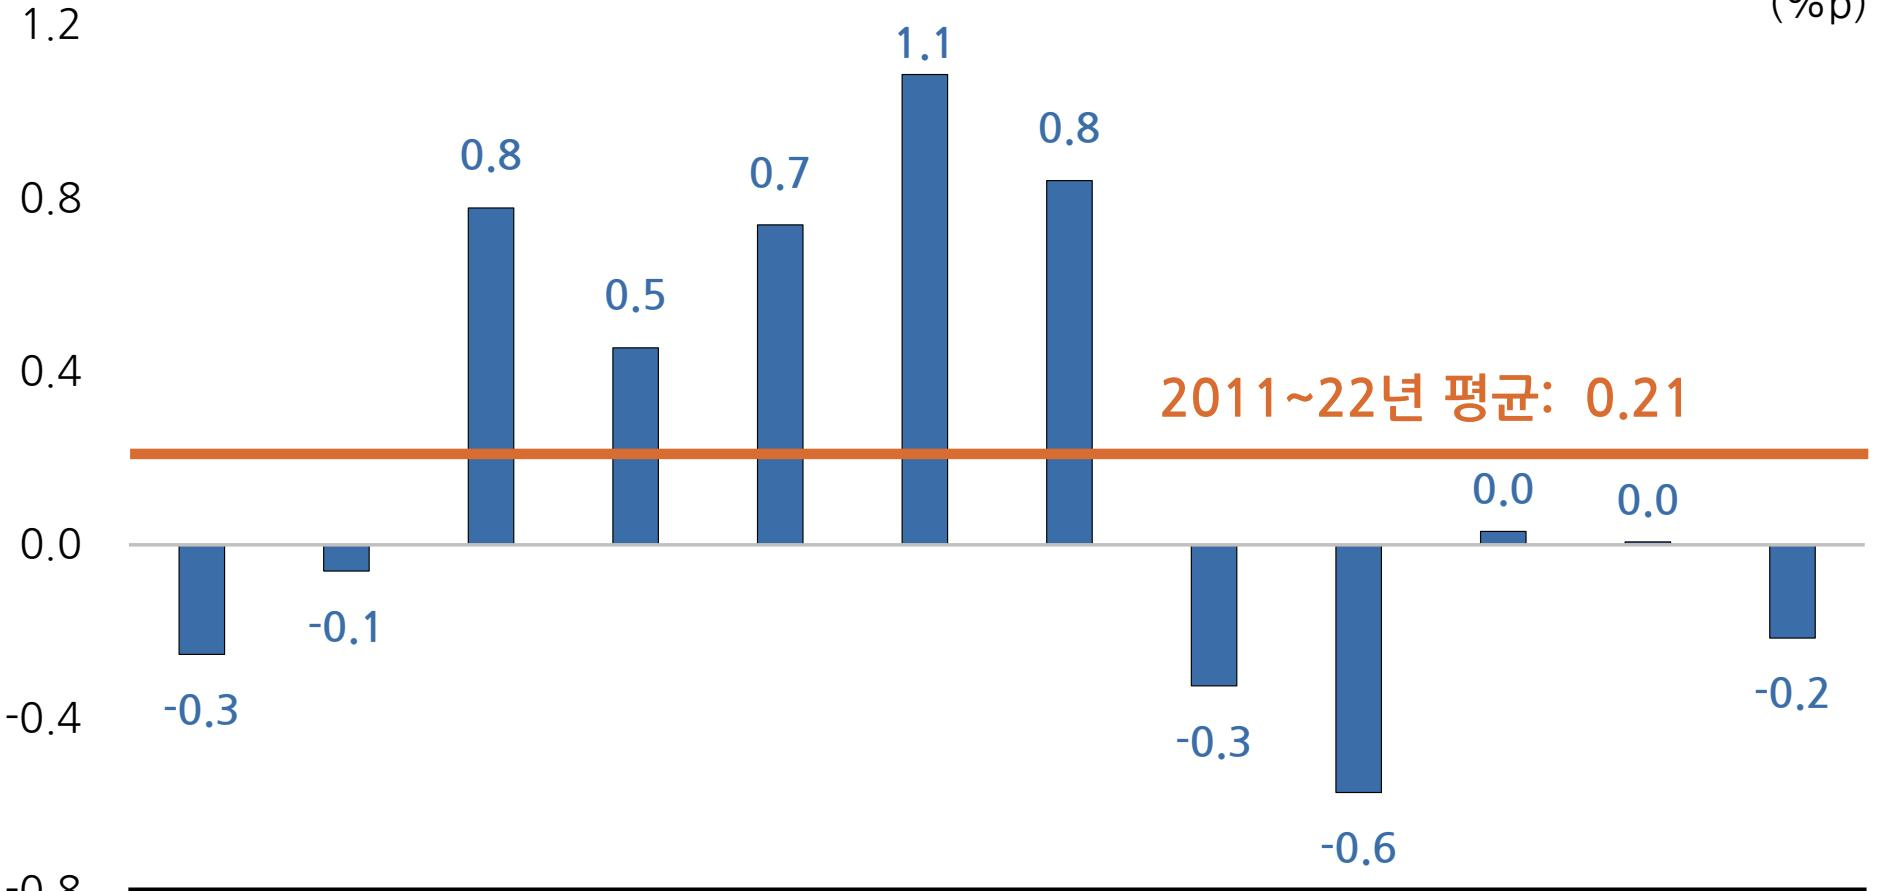

In [30]:
# 한계 사례: 원래 1번 질문 (정답: 2016년 1.1%p — 12쪽 차트)
limit_q = "2011~2022년 중 주택건설의 경제성장 기여도가 가장 높았던 해와 그 수치가 얼마인지 알려줘"

docs = retriever.invoke(limit_q)
kinds = [source_kind(doc.page_content if isinstance(doc, Document) else doc) for doc in docs]
print("질문(Q):", limit_q)
print("[근거 원본]", ", ".join(f"{k} {n}건" for k, n in Counter(kinds).most_common()))
print("\n[BEFORE] 텍스트 전용 RAG\n", text_only_chain.invoke(limit_q))
print("\n[AFTER ] 멀티모달 RAG\n", chain.invoke(limit_q))

# 증거: 추출된 그림에는 차트 제목과 가로축(연도)이 잘려 있습니다.
limit_img = figures_dir / "figure-12-15.jpg"
if limit_img.exists():
    print("\n[추출된 그림] figure-12-15.jpg  ← 12쪽 '주택건설의 성장기여도' 차트")
    display(Image(filename=str(limit_img), width=500))

**원인**
- PDF 원본 12쪽에는 차트 제목(`주택건설의 성장기여도`)과 가로축 연도(2011~2022)가 있지만, Unstructured 가 잘라 낸 그림(`figure-12-15.jpg`)에는 **막대와 수치만 남고 제목·연도가 없음**
- 이미지 요약도 연도를 알 수 없어 `해 미제공`이라고 적거나 연도를 추정해서 적었고, 답변 단계에서는 "몇 년인지 알 수 없다"고 답변함
- 본문 텍스트에도 연도별 수치는 없어서(연평균 0.21, 변동폭 0.48만 있음) 이 질문은 이 파이프라인으로 답할 수 없음 
   → **추출 단계에서 정보가 사라지면 검색·생성 단계에서 복구할 수 없다**는 한계 사례.